# Batch correction: uoe5 lysosome features (automated plates)

Same approach as the nucleus batch-correction notebook, run on the lysosome ROI table:

1. Transform ROI-level features, aggregate to wells (median + IQR)
2. Correct per plate using the parental (KOLF2.1J) wells, **fit on parentals only**
3. Evaluate on held-out parental wells (plate omega-squared vs a permutation null)
4. Per-variant effects in plate-matched units, calibrated against the REV/WT revertants
5. Allelic-series (REV < het < hom) consistency test

Helpers live in `notebooks/batch_correction_utils.py`. Automated and manual plates are analysed separately, so this notebook only loads `Source == "automated"`.

In [1]:
import sys, pathlib, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NB_DIR = pathlib.Path("/data/kelpschdj/iNDI/Production/notebooks")
sys.path.insert(0, str(NB_DIR))
import batch_correction_utils as bc
importlib.reload(bc)      # pick up edits to the module without restarting the kernel

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

## Config

In [2]:
ORGANELLE_FN = "/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_organelle_output.parquet"
STRUCTURE = "Lysosome"
SOURCE    = "automated"

# ROI-level candidate features (same list as uoe5_lysosome_PCA.ipynb)
RAW_FEATURES = [
    "area_px", "organelle_count", "average_organelle_area", "roi_occupancy",
    "max_f_intensity", "sum_f_intensity", "mean_f_intensity",
    "median_f_intensity", "CoefOfVar_intensity",
    "area_median", "area_std",
    "perimeter_median", "eccentricity_median", "solidity_median",
    "extent_median", "axis_major_length_median", "axis_minor_length_median",
    "equivalent_diameter_area_median",
    "intensity_mean_median", "intensity_max_median", "intensity_min_median",
    "dist_to_centroid_median", "dist_to_centroid_norm_mean", "dist_to_centroid_std",
]
META_COLS = ["Gene", "Variant", "Genotype", "Gene_Var_Type", "Genotype_Name",
             "Batch", "Source", "JAX_ID", "Asp PosID"]
PARENTAL_COL, PARENTAL_VALUE = "Gene", "KOLF2.1J"
N_SEEDS = 20

## Load lysosome ROIs (automated only)

In [3]:
df = pd.read_parquet(
    ORGANELLE_FN,
    filters=[("Structure", "==", STRUCTURE), ("Source", "==", SOURCE)],   # read only what we need
)
df["Batch"] = df["Batch"].astype("Int64").astype(str)

# Well_ID fallback (same construction as uoe5_analysis.ipynb)
if "Well_ID" not in df.columns:
    import string
    df["Well_ID"] = df.apply(
        lambda r: f"{string.ascii_uppercase[int(r['Row'])-1]}{int(r['Column']):02d}", axis=1)

print(df.shape)
missing = [c for c in bc.WELL_KEYS + [PARENTAL_COL, "Gene_Var_Type"] + RAW_FEATURES if c not in df.columns]
print("missing columns:", missing)
assert not missing, "fix RAW_FEATURES / column names above"

(576259, 105)
missing columns: []


In [4]:
# Sanity checks before transforming
wells_per_plate = df.groupby("iNDI_Plate_ID")["Well_ID"].nunique()
par_mask = df[PARENTAL_COL] == PARENTAL_VALUE
print(f"plates: {df['iNDI_Plate_ID'].nunique()} | parental wells: "
      f"{df.loc[par_mask, bc.WELL_KEYS].drop_duplicates().shape[0]}  (nucleus run had ~1140)")
print(df.loc[par_mask].groupby("iNDI_Plate_ID")["Well_ID"].nunique().rename("parental_wells").to_frame().T)

nan_frac = df[RAW_FEATURES].replace([np.inf, -np.inf], np.nan).isna().mean().sort_values(ascending=False)
print("\nfraction NaN/inf per raw feature (ROIs with no lysosome objects are likely NaN):")
print(nan_frac[nan_frac > 0].round(3))

plates: 13 | parental wells: 1139  (nucleus run had ~1140)
iNDI_Plate_ID   INDI00002D  INDI00007D  INDI00011D  INDI00015D  INDI00019D  INDI00023D  INDI00026D  INDI00035D  INDI00039D  INDI00043D  INDI00047D  INDI00049D  INDI00053D
parental_wells          96          48          96          48          95          96          92          96          96          96          95          91          94

fraction NaN/inf per raw feature (ROIs with no lysosome objects are likely NaN):
Series([], dtype: float64)


## 1. Transforms
`auto_transform` picks log1p for right-skewed non-negative features, logit for skewed fractions, and leaves the rest. **Read the report** and override anything that looks wrong before moving on.

In [5]:
df_t, report, tcols = bc.auto_transform(df, RAW_FEATURES)
report

,transform,skew_raw,skew_t,frac_nan,min,max
feature,,,,,,
area_px,none,0.82,0.82,0.0,15.000000,1.305200e+04
organelle_count,none,0.34,0.34,0.0,1.000000,1.570000e+02
average_organelle_area,log1p,17.79,0.47,0.0,15.000000,3.356000e+03
roi_occupancy,none,0.82,0.82,0.0,0.000332,2.885125e-01
max_f_intensity,log1p,2.40,-0.65,0.0,219.000000,6.553500e+04
sum_f_intensity,log1p,1.43,-1.67,0.0,3342.000000,1.149165e+08
mean_f_intensity,log1p,4.03,-0.82,0.0,193.347826,4.628221e+04
median_f_intensity,log1p,5.96,-0.82,0.0,193.000000,6.553500e+04
CoefOfVar_intensity,log1p,1.24,0.60,0.0,0.019288,2.397599e+00


## 2. Well-level table
Median and IQR of each transformed feature per well, plus ROI count and the fraction of ROIs with zero objects. Features that are mostly NaN, constant or zero-inflated are dropped, then near-duplicates (|r| > 0.9 on plate-centred parental wells) are pruned. `_med` columns come first, so they win ties against `_iqr`.

In [6]:
wells, WF = bc.build_well_table(df_t, tcols, meta_cols=META_COLS, count_col="organelle_count",
                                parental_col=PARENTAL_COL, parental_value=PARENTAL_VALUE)
WF = bc.finalize_features(wells, WF)
FEATS, dropped_pairs = bc.prune_correlated(wells, WF, thresh=0.9, mask=wells["is_parental"])

print(f"wells: {len(wells)} | parental: {int(wells['is_parental'].sum())} | "
      f"features: {len(WF)} -> {len(FEATS)} after correlation pruning")
print("dropped as redundant (feature, kept-instead, |r|):")
for d in dropped_pairs:
    print("  ", d)

dropped frac_roi_zero: nan_frac=0.000, sd=0
wells: 3739 | parental: 1139 | features: 49 -> 36 after correlation pruning
dropped as redundant (feature, kept-instead, |r|):
   ('t_roi_occupancy_med', 't_area_px_med', np.float64(1.0))
   ('t_median_f_intensity_med', 't_mean_f_intensity_med', np.float64(0.988))
   ('t_area_std_med', 't_average_organelle_area_med', np.float64(0.968))
   ('t_equivalent_diameter_area_median_med', 't_area_median_med', np.float64(1.0))
   ('t_intensity_mean_median_med', 't_mean_f_intensity_med', np.float64(0.954))
   ('t_intensity_max_median_med', 't_mean_f_intensity_med', np.float64(0.961))
   ('t_intensity_min_median_med', 't_mean_f_intensity_med', np.float64(0.909))
   ('t_dist_to_centroid_norm_mean_med', 't_dist_to_centroid_median_med', np.float64(0.971))
   ('t_roi_occupancy_iqr', 't_area_px_iqr', np.float64(1.0))
   ('t_median_f_intensity_iqr', 't_mean_f_intensity_iqr', np.float64(0.949))
   ('t_area_std_iqr', 't_average_organelle_area_iqr', np.float64(0.

## 3. Evaluate correction methods on held-out parentals
Each seed splits every plate's parental wells into a fit half and an evaluation half. Plate omega-squared is measured on the held-out half only (so the test isn't circular) and compared with a permutation null. M1b_shrink shrinks per-plate centres toward the grand centre, so features with no real plate effect are not given extra noise.

In [7]:
methods = {
    "M0":         lambda w, p, f: w,
    "M1":         lambda w, p, f: bc.robust_z(w, p, f, pooled_scale=False),
    "M1b":        lambda w, p, f: bc.robust_z(w, p, f, pooled_scale=True),
    "M1b_shrink": lambda w, p, f: bc.robust_z(w, p, f, pooled_scale=True, shrink=True),
}
results = {name: bc.eval_method(wells, fn, FEATS, seeds=range(N_SEEDS)) for name, fn in methods.items()}

tab = pd.concat({name: r.groupby(level=0)["obs"].mean() for name, r in results.items()}, axis=1)
tab["null"] = results["M0"].groupby(level=0)["null"].mean()
tab = tab.sort_values("M0", ascending=False)
print(tab.round(3))
print("\nmean (obs - null) across features:")
print((tab[list(methods)].sub(tab["null"], axis=0)).mean().round(3))

                                     M0     M1    M1b  M1b_shrink   null
t_max_f_intensity_med             0.493  0.029  0.024       0.025  0.003
t_axis_minor_length_median_med    0.492  0.045  0.040       0.037  0.002
t_mean_f_intensity_med            0.463  0.025  0.036       0.038  0.004
t_eccentricity_median_med         0.436  0.025  0.029       0.030  0.003
t_solidity_median_med             0.421  0.036  0.029       0.030  0.005
t_solidity_median_iqr             0.412  0.020  0.020       0.022  0.004
t_extent_median_med               0.406  0.037  0.034       0.036  0.002
t_area_median_med                 0.353  0.048  0.031       0.028  0.004
log_n_rois                        0.292  0.036  0.037       0.042  0.004
t_axis_major_length_median_iqr    0.281  0.039  0.035       0.033  0.001
t_extent_median_iqr               0.277  0.023  0.024       0.024  0.003
t_sum_f_intensity_med             0.269  0.034  0.039       0.038  0.006
t_perimeter_median_med            0.264  0.023  0.0

## 4. Final correction and variant effects
Fit on **all** parental wells (no holdout), then compute plate-matched effects: median(variant wells) - median(parental wells on the same plate), in pooled robust-SD units. The REV/WT lines are the noise model: the spread of their effects is clone-level noise (these lines went through two engineering rounds, so they're an imperfect null).

In [8]:
METHOD = dict(pooled_scale=True, shrink=False)    # change after looking at the table above
corr = bc.robust_z(wells, wells[wells["is_parental"]], FEATS, **METHOD)

eff = bc.compute_effects(corr, FEATS)
eff, rev_sd, rev_p95 = bc.add_rev_z(eff)
rev, non = eff[eff["is_rev"]], eff[~eff["is_rev"]]

print("|effect| distribution (all features pooled):")
print(eff.groupby("is_rev")["effect"].apply(lambda s: s.abs().describe()).unstack().round(2))

feat_summary = pd.DataFrame({
    "rev_sd": rev_sd,
    "rev_p95": rev_p95,
    "frac_nonrev_beyond_p95": {f: (non.loc[non.feature == f, "effect"].abs() > rev_p95[f]).mean() for f in rev_p95.index},
}).round(3)
feat_summary["n_nonrev"] = non.groupby("feature").size()
feat_summary.sort_values("frac_nonrev_beyond_p95", ascending=False)

|effect| distribution (all features pooled):
         count  mean  std  min   25%   50%   75%   max
is_rev                                                
False   1332.0  0.62  0.9  0.0  0.16  0.36  0.72  9.66
True     612.0  0.66  0.9  0.0  0.16  0.39  0.76  6.97


,rev_sd,rev_p95,frac_nonrev_beyond_p95,n_nonrev
t_eccentricity_median_iqr,0.331,0.585,0.162,37
t_max_f_intensity_med,0.283,1.191,0.108,37
t_axis_major_length_median_iqr,0.426,1.353,0.108,37
t_max_f_intensity_iqr,0.283,0.956,0.108,37
t_perimeter_median_med,0.368,1.124,0.108,37
t_sum_f_intensity_iqr,0.513,0.997,0.081,37
t_dist_to_centroid_norm_mean_iqr,0.209,0.826,0.081,37
t_perimeter_median_iqr,0.534,1.327,0.054,37
t_solidity_median_med,1.122,4.519,0.054,37
t_mean_f_intensity_med,0.564,1.994,0.054,37


In [9]:
# Tails: are variants more extreme than revertants? (a normal null would give ~4.6% beyond 2 and ~0.3% beyond 3)
print(eff.groupby("is_rev")["abs_z"].agg(n="size", gt2=lambda s: (s > 2).mean(), gt3=lambda s: (s > 3).mean()).round(3))

# Are strong hits concentrated on a few plates?
by_plate = (non.assign(abs_z=non["z_rev"].abs()).assign(hit=lambda d: d["abs_z"] > 3)
            .groupby("plate")["hit"].agg(["sum", "size"]))
by_plate["frac"] = by_plate["sum"] / by_plate["size"]
print(by_plate.sort_values("frac", ascending=False).round(2))

top = (non.assign(abs_z=non["z_rev"].abs()).sort_values("abs_z", ascending=False)
       [["Gene_Var_Type", "plate", "feature", "effect", "z_rev"]].head(25))
top.round(2)

           n    gt2    gt3
is_rev                    
False   1332  0.137  0.064
True     612  0.155  0.080
            sum  size  frac
plate                      
INDI00015D   48   180  0.27
INDI00019D    9    36  0.25
INDI00049D    8   144  0.06
INDI00043D    6   108  0.06
INDI00002D    6   144  0.04
INDI00039D    2    72  0.03
INDI00035D    4   144  0.03
INDI00047D    1    72  0.01
INDI00053D    1   108  0.01
INDI00007D    0   108  0.00
INDI00011D    0    72  0.00
INDI00023D    0    72  0.00
INDI00026D    0    72  0.00


,Gene_Var_Type,plate,feature,effect,z_rev
1171,PSEN1_E276A_SNV/WT,INDI00015D,t_max_f_intensity_iqr,6.60,23.34
1174,PSEN1_E276A_SNV/WT,INDI00015D,t_CoefOfVar_intensity_iqr,6.47,22.21
1173,PSEN1_E276A_SNV/WT,INDI00015D,t_mean_f_intensity_iqr,9.66,17.27
1170,PSEN1_E276A_SNV/WT,INDI00015D,t_average_organelle_area_iqr,9.30,16.19
1166,PSEN1_E276A_SNV/WT,INDI00015D,t_dist_to_centroid_median_med,-5.49,-14.61
1155,PSEN1_E276A_SNV/WT,INDI00015D,t_max_f_intensity_med,-3.74,-13.20
1157,PSEN1_E276A_SNV/WT,INDI00015D,t_mean_f_intensity_med,-7.41,-13.13
1179,PSEN1_E276A_SNV/WT,INDI00015D,t_extent_median_iqr,4.78,11.55
687,GRN_Q125X_SNV/SNV,INDI00049D,t_max_f_intensity_med,3.27,11.53
1182,PSEN1_E276A_SNV/WT,INDI00015D,t_intensity_mean_median_iqr,8.02,10.33


## 5. Allelic-series test
Under no effect, a series is monotone (REV < het < hom or the reverse) in 2 of 6 orderings = 1/3. Features are correlated, so p-values are not independent; treat this as a lead, not a verdict.

In [10]:
bc.series_monotone_test(eff)

,feature,n_series,n_monotone,frac,p_vs_1_3
0,t_CoefOfVar_intensity_med,15,7,0.47,0.203
1,t_area_px_iqr,15,7,0.47,0.203
2,t_organelle_count_med,15,7,0.47,0.203
3,t_extent_median_iqr,15,7,0.47,0.203
4,t_max_f_intensity_med,15,7,0.47,0.203
5,t_mean_f_intensity_med,15,7,0.47,0.203
6,t_CoefOfVar_intensity_iqr,15,6,0.40,0.382
7,t_axis_major_length_median_med,15,6,0.40,0.382
8,t_organelle_count_iqr,15,6,0.40,0.382
9,t_intensity_min_median_iqr,15,5,0.33,0.596


## Next
- Compare lysosome vs nucleus: which features carry a plate effect, and how large is the revertant spread relative to the effects?
- Check position effects (row, column, Asp PosID) among parental wells on a single plate.
- Clone replicates (the two APOE genotypes with two `JAX_ID`s) give a direct clone-noise estimate: rerun `compute_effects` grouping by `JAX_ID`.
- Repeat for endosome and mitochondria by changing `STRUCTURE`.

saved: Lysosome_heldout_parental_pca.png, Lysosome_all_wells_pca.png, Lysosome_feature_boxplots.png, Lysosome_omega_bars.png


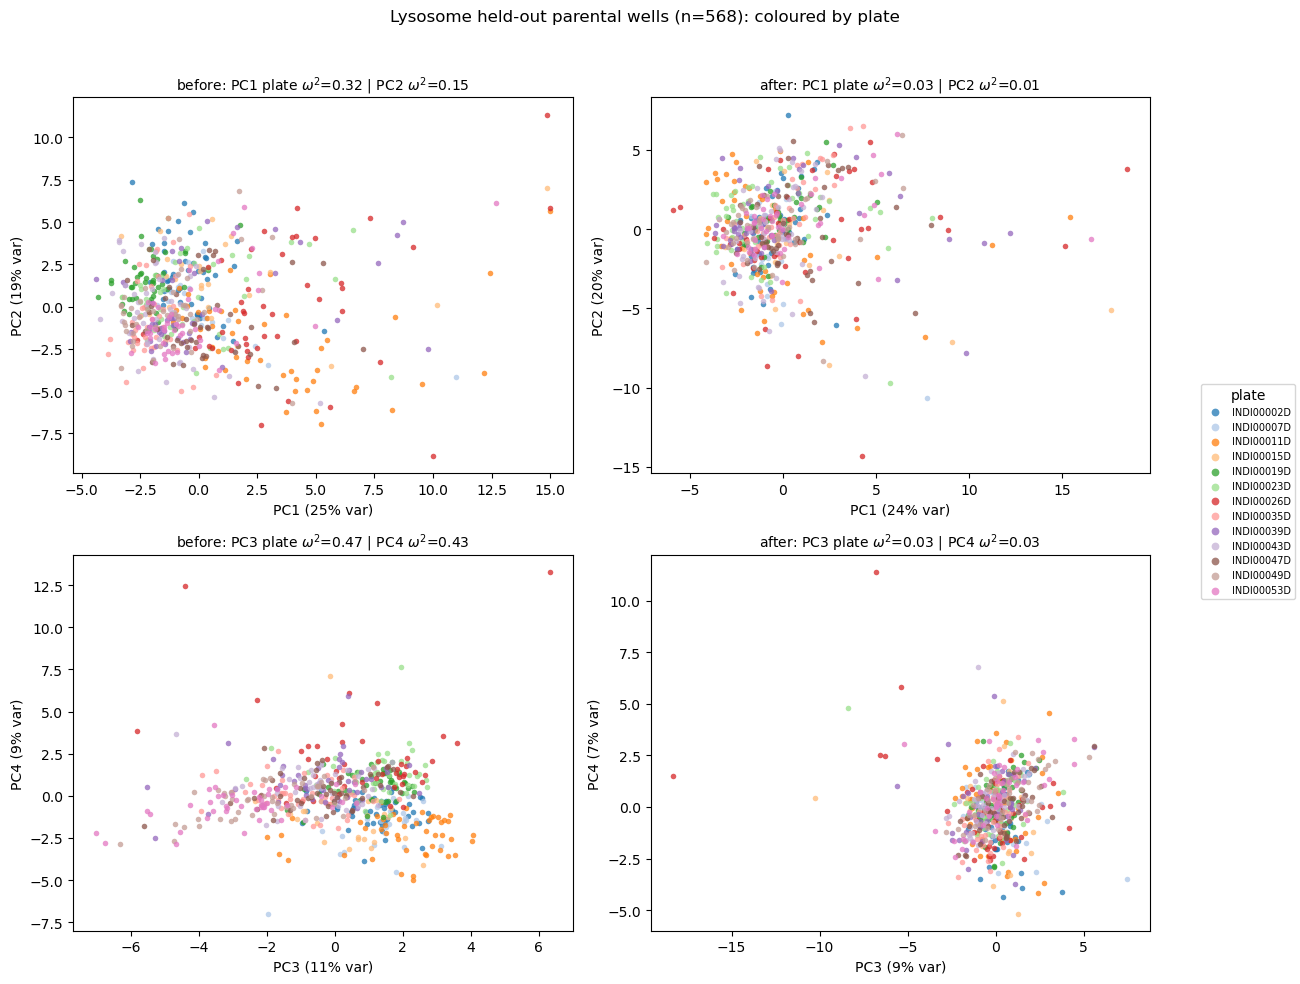

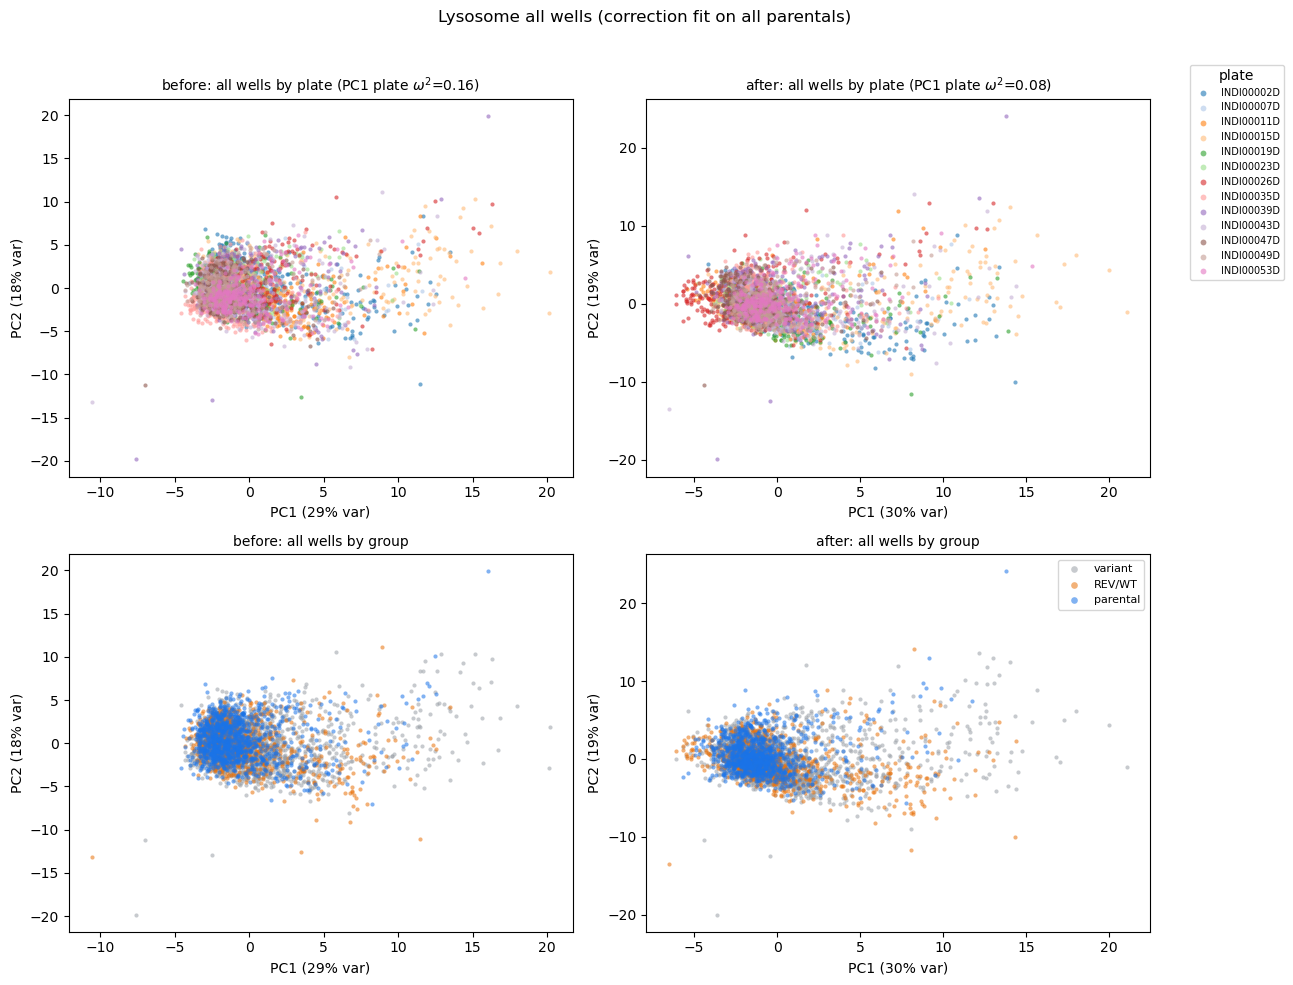

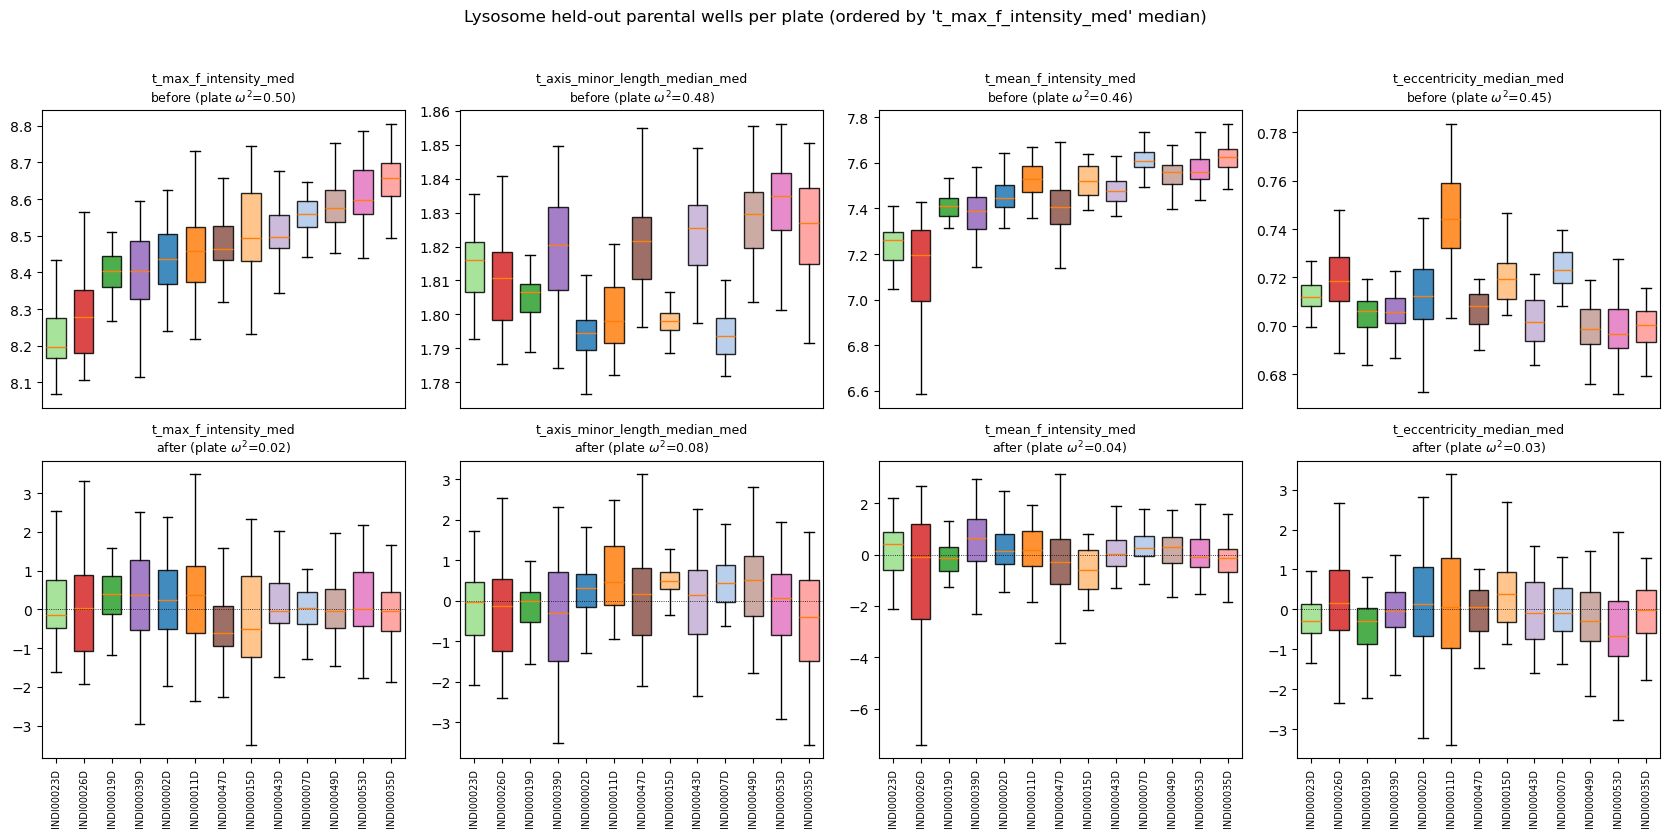

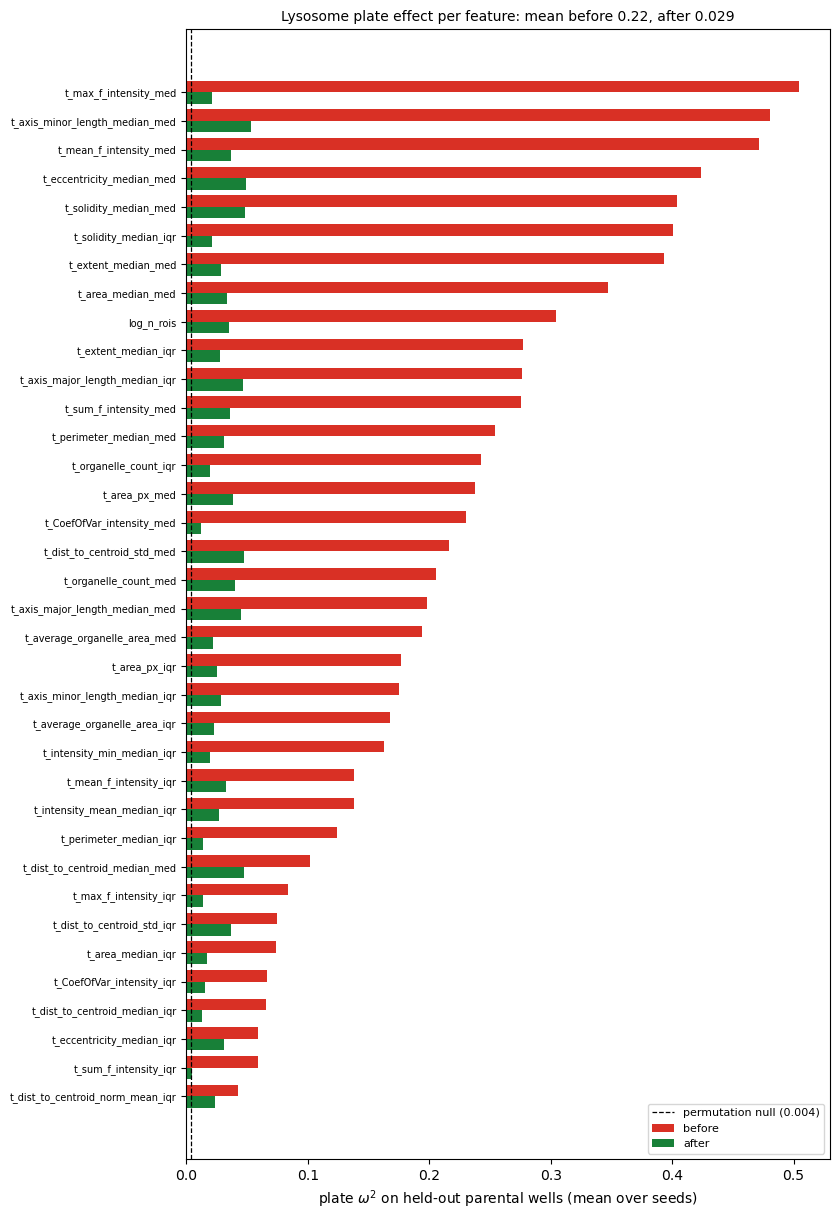

{'heldout_parental_pca': <Figure size 1300x1000 with 4 Axes>,
 'all_wells_pca': <Figure size 1300x1000 with 4 Axes>,
 'feature_boxplots': <Figure size 1680x850 with 8 Axes>,
 'omega_bars': <Figure size 850x1230 with 1 Axes>}

In [11]:
# lysosome notebook
bc.normalization_report(wells, FEATS, corrected=corr, tag="Lysosome",
                        outdir="/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/figures_normalization")